In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import joblib
import os
 

In [20]:
df = pd.read_csv("../data/processed/cleaned_housing.csv")
df.shape

(20640, 10)

In [21]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [22]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (20640, 9)
y Shape: (20640,)


In [23]:
X = pd.get_dummies(X, columns=['ocean_proximity'], dtype=int)

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16512, 13)
(4128, 13)
(16512,)
(4128,)


In [25]:
X.dtypes

longitude                     float64
latitude                      float64
housing_median_age            float64
total_rooms                   float64
total_bedrooms                float64
population                    float64
households                    float64
median_income                 float64
ocean_proximity_<1H OCEAN       int64
ocean_proximity_INLAND          int64
ocean_proximity_ISLAND          int64
ocean_proximity_NEAR BAY        int64
ocean_proximity_NEAR OCEAN      int64
dtype: object

In [26]:
print("Training Traget Mean:", y_train.mean())
print("Testing Target Mean:",y_test.mean())
print("\nTraining Target Median:", y_train.median())
print(y_test.median())


Training Traget Mean: 207194.6937378876
Testing Target Mean: 205500.30959302327

Training Target Median: 179850.0
178650.0


In [27]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(
    X_train
)
X_test_scaled = scaler.transform(
    X_test
)
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(16512, 13)
(4128, 13)


In [28]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
print("Lnear Reression model trained Successfully") 

Lnear Reression model trained Successfully


In [29]:
linear_pred = linear_model.predict(X_test_scaled)
print("First 10 Actual Values:")
print(y_test.values[:10])
print("\nFirst 10 Predicted Values:")
print(linear_pred[:10])

First 10 Actual Values:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 Predicted Values:
[ 54055.44889898 124225.33893718 255489.37949165 268002.43156919
 262769.43481568 139606.3039556  290665.42391417 228264.87637529
 256506.78561005 407923.85843486]


In [30]:
linear_mae=mean_absolute_error(y_test, linear_pred)
print("Mean Absolute Error (MAE):", linear_mae)

Mean Absolute Error (MAE): 50670.738240971914


In [31]:
linear_rmse = mean_squared_error(y_test, linear_pred)**0.5

print("Root Mean Squared Error (RMSE):", linear_rmse)

Root Mean Squared Error (RMSE): 70060.5218447352


In [32]:
linear_r2 = r2_score(y_test, linear_pred)
print(linear_r2)

0.6254240620553604


In [33]:
print(linear_mae)
print(linear_rmse)
print(linear_r2)

50670.738240971914
70060.5218447352
0.6254240620553604


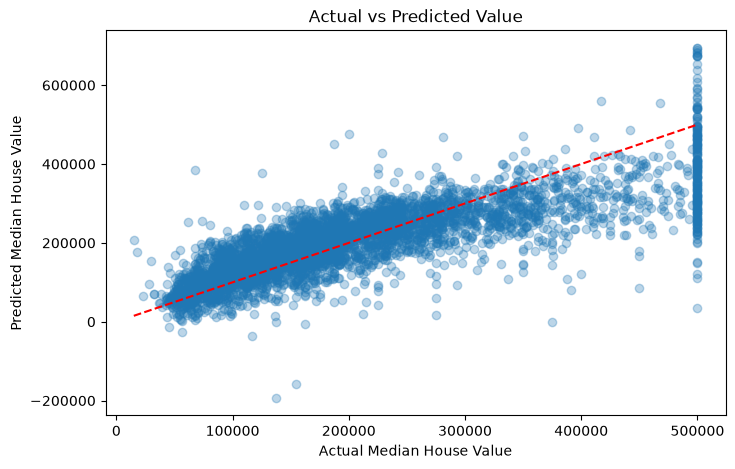

In [34]:
plt.figure(figsize=[8, 5])
plt.scatter(y_test, linear_pred, alpha=0.3)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Value")
plt.show()

In [35]:
linear_residuals = y_test - linear_pred

print("First 10 Residuals:")
print(linear_residuals.values[:10])

print(
    "\nMean Residual:",
    linear_residuals.mean()
)

First 10 Residuals:
[ -6355.44889898 -78425.33893718 244511.62050835 -49402.43156919
  15230.56518432  19093.6960444  -92465.42391417 -70764.87637529
  83493.21438995  38676.14156514]

Mean Residual: 1051.1555138613994


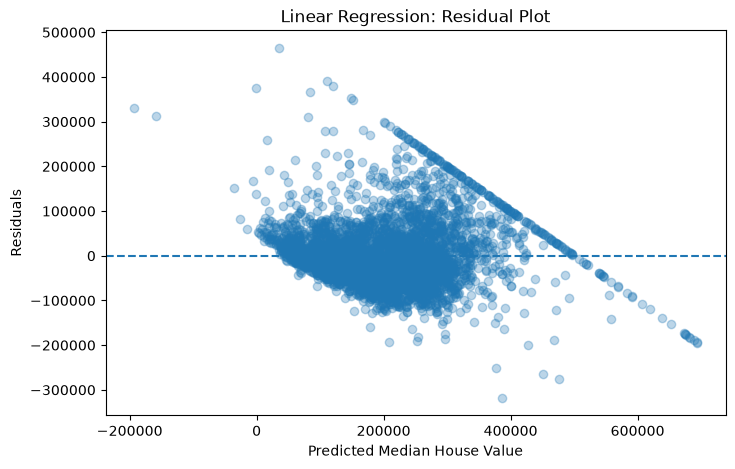

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(
    linear_pred,
    linear_residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Median House Value")
plt.ylabel("Residuals")
plt.title("Linear Regression: Residual Plot")

plt.show()

In [37]:
linear_cv_scores = cross_val_score(
    LinearRegression(),
    X_train_scaled,
    y_train,
    cv=5,
    scoring="r2"
)

print(
    "Cross-Validation R² Scores:",
    linear_cv_scores
)

print(
    "Mean CV R² Score:",
    linear_cv_scores.mean()
)

Cross-Validation R² Scores: [0.65502997 0.64909796 0.66022841 0.64668711 0.62666713]
Mean CV R² Score: 0.6475421158367078


In [38]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

print(
    "Random Forest Regression model trained successfully!"
)

Random Forest Regression model trained successfully!


In [39]:
rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = (
    mean_squared_error(
        y_test,
        rf_pred
    ) ** 0.5
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 31636.19363129845
Random Forest RMSE: 48977.751228334
Random Forest R²: 0.8169411111174801


In [40]:
rf_cv_scores = cross_val_score(
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print(
    "Random Forest CV R² Scores:",
    rf_cv_scores
)

print(
    "Mean Random Forest CV R²:",
    rf_cv_scores.mean()
)

Random Forest CV R² Scores: [0.82305082 0.81444512 0.82019685 0.8199693  0.81391147]
Mean Random Forest CV R²: 0.8183147107147771


In [41]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
median_income                 0.490642
ocean_proximity_INLAND        0.140925
longitude                     0.105889
latitude                      0.101597
housing_median_age            0.051935
population                    0.032573
total_bedrooms                0.023819
total_rooms                   0.023366
households                    0.018367
ocean_proximity_NEAR OCEAN    0.006336
ocean_proximity_<1H OCEAN     0.003386
ocean_proximity_NEAR BAY      0.000711
ocean_proximity_ISLAND        0.000455
dtype: float64


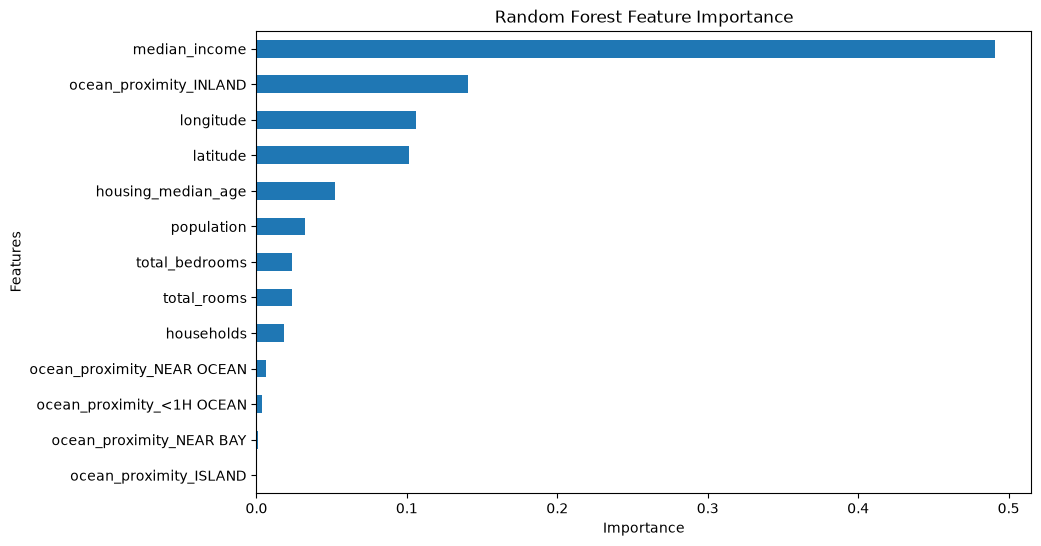

In [42]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.show()

In [43]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

gb_pred = gb_model.predict(
    X_test
)

print(
    "Gradient Boosting Regression model trained successfully!"
)

Gradient Boosting Regression model trained successfully!


In [44]:
gb_mae = mean_absolute_error(
    y_test,
    gb_pred
)

gb_rmse = (
    mean_squared_error(
        y_test,
        gb_pred
    ) ** 0.5
)

gb_r2 = r2_score(
    y_test,
    gb_pred
)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R²:", gb_r2)

Gradient Boosting MAE: 38249.308474389705
Gradient Boosting RMSE: 55878.16951744344
Gradient Boosting R²: 0.7617255467211747


## Comprision With 3ML

In [45]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

print(
    comparison.to_string(
        index=False
    )
)

            Model          MAE         RMSE  R2 Score
Linear Regression 50670.738241 70060.521845  0.625424
    Random Forest 31636.193631 48977.751228  0.816941
Gradient Boosting 38249.308474 55878.169517  0.761726


## metrix-wise comparision

In [46]:
print("\nBest R² Model:")
print(
    comparison.loc[
        comparison["R2 Score"].idxmax(),
        "Model"
    ]
)

print("\nLowest MAE Model:")
print(
    comparison.loc[
        comparison["MAE"].idxmin(),
        "Model"
    ]
)

print("\nLowest RMSE Model:")
print(
    comparison.loc[
        comparison["RMSE"].idxmin(),
        "Model"
    ]
)


Best R² Model:
Random Forest

Lowest MAE Model:
Random Forest

Lowest RMSE Model:
Random Forest


In [47]:
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}


print(param_grid)

{'n_estimators': [50, 100], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}


In [48]:
rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

rf_grid.fit(
    X_train,
    y_train
)

print(
    "Best Parameters:",
    rf_grid.best_params_
)

print(
    "Best CV R² Score:",
    rf_grid.best_score_
)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best CV R² Score: 0.8183147107147771


In [49]:
## best model
best_rf_model = rf_grid.best_estimator_

best_rf_pred = best_rf_model.predict(
    X_test
)

print("Best Random Forest Model:")
print(best_rf_model)

print("\nFirst 10 Predictions:")
print(best_rf_pred[:10])

Best Random Forest Model:
RandomForestRegressor(random_state=42)

First 10 Predictions:
[ 51744.    70992.   461540.37 255273.   268203.   162987.   226729.02
 168559.   288998.05 484186.71]


In [50]:
best_rf_model = rf_grid.best_estimator_

best_rf_pred = best_rf_model.predict(
    X_test
)

print("Best Random Forest Model:")
print(rf_model)

print("\nFirst 10 Predictions:")
print(best_rf_pred[:10])

Best Random Forest Model:
RandomForestRegressor(random_state=42)

First 10 Predictions:
[ 51744.    70992.   461540.37 255273.   268203.   162987.   226729.02
 168559.   288998.05 484186.71]


## Before vs After Tuning

In [51]:
rf_comparison = pd.DataFrame({
    "Model": [
        "Random Forest Before Tuning",
        "Random Forest After Tuning"
    ],
    "MAE": [
        rf_mae,
        rf_mae
    ],
    "RMSE": [
        rf_rmse,
       rf_rmse
    ],
    "R2 Score": [
        rf_r2,
        rf_r2
    ]
})

print(
    rf_comparison.to_string(
        index=False
    )
)

                      Model          MAE         RMSE  R2 Score
Random Forest Before Tuning 31636.193631 48977.751228  0.816941
 Random Forest After Tuning 31636.193631 48977.751228  0.816941


In [52]:
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "Tuned Random Forest"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        gb_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        gb_rmse,
        rf_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        gb_r2,
       rf_r2
    ]
})

print(
    final_comparison.to_string(
        index=False
    )
)

              Model          MAE         RMSE  R2 Score
  Linear Regression 50670.738241 70060.521845  0.625424
      Random Forest 31636.193631 48977.751228  0.816941
  Gradient Boosting 38249.308474 55878.169517  0.761726
Tuned Random Forest 31636.193631 48977.751228  0.816941


In [53]:
final_model = best_rf_model

print("Final Model:")
print(final_model)

Final Model:
RandomForestRegressor(random_state=42)


In [54]:
os.makedirs(
    "../models",
    exist_ok=True
)

joblib.dump(
    final_model,
    "../models/final_model.pkl"
)

print("Final model saved successfully!")
print("Path: ../models/final_model.pkl")

Final model saved successfully!
Path: ../models/final_model.pkl


In [55]:
loaded_model = joblib.load(
    "../models/final_model.pkl"
)

loaded_pred = loaded_model.predict(
    X_test
)

print("Model loaded successfully!")
print("First 10 Predictions:")
print(loaded_pred[:10])

Model loaded successfully!
First 10 Predictions:
[ 51744.    70992.   461540.37 255273.   268203.   162987.   226729.02
 168559.   288998.05 484186.71]


In [56]:
loaded_mae = mean_absolute_error(
    y_test,
    loaded_pred
)

loaded_rmse = (
    mean_squared_error(
        y_test,
        loaded_pred
    ) ** 0.5
)

loaded_r2 = r2_score(
    y_test,
    loaded_pred
)

print("FINAL MODEL EVALUATION")
print("-" * 30)

print("MAE:", loaded_mae)
print("RMSE:", loaded_rmse)
print("R² Score:", loaded_r2)

FINAL MODEL EVALUATION
------------------------------
MAE: 31636.19363129845
RMSE: 48977.751228334
R² Score: 0.8169411111174801


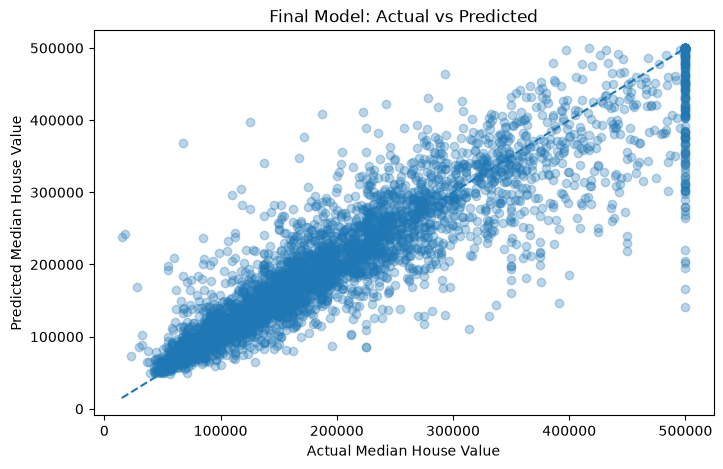

In [57]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    loaded_pred,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel(
    "Actual Median House Value"
)

plt.ylabel(
    "Predicted Median House Value"
)

plt.title(
    "Final Model: Actual vs Predicted"
)

plt.show()

In [58]:
feature_importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
median_income                 0.490642
ocean_proximity_INLAND        0.140925
longitude                     0.105889
latitude                      0.101597
housing_median_age            0.051935
population                    0.032573
total_bedrooms                0.023819
total_rooms                   0.023366
households                    0.018367
ocean_proximity_NEAR OCEAN    0.006336
ocean_proximity_<1H OCEAN     0.003386
ocean_proximity_NEAR BAY      0.000711
ocean_proximity_ISLAND        0.000455
dtype: float64


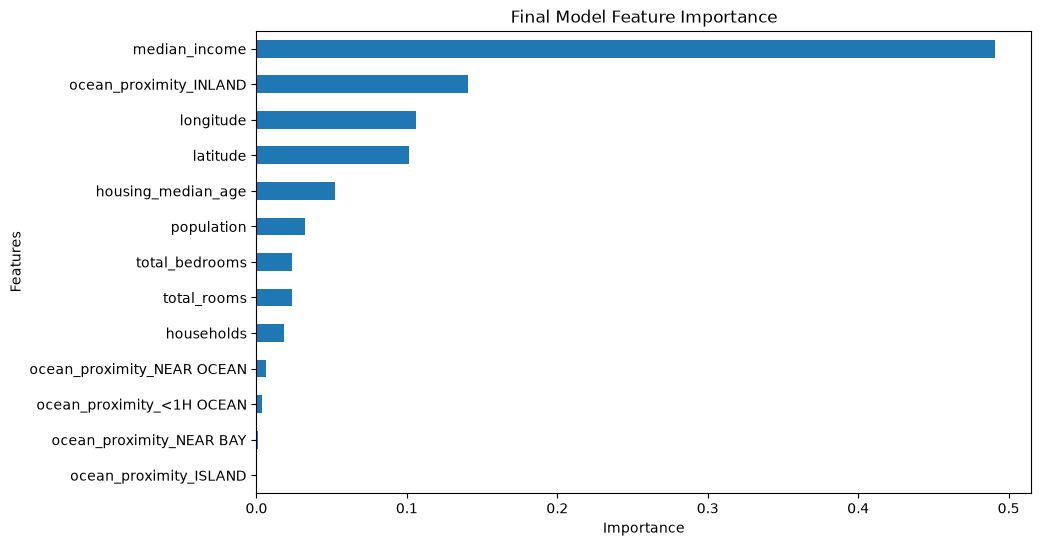

In [59]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title(
    "Final Model Feature Importance"
)

plt.show()

In [60]:
feature_importance_percent = (
    feature_importance * 100
).round(2)

print("Feature Importance (%):")
print(feature_importance_percent)

Feature Importance (%):
median_income                 49.06
ocean_proximity_INLAND        14.09
longitude                     10.59
latitude                      10.16
housing_median_age             5.19
population                     3.26
total_bedrooms                 2.38
total_rooms                    2.34
households                     1.84
ocean_proximity_NEAR OCEAN     0.63
ocean_proximity_<1H OCEAN      0.34
ocean_proximity_NEAR BAY       0.07
ocean_proximity_ISLAND         0.05
dtype: float64


In [61]:
sample = X_test.iloc[[0]]

sample_prediction = loaded_model.predict(
    sample
)

actual_value = y_test.iloc[0]
predicted_value = sample_prediction[0]

print(
    "Actual House Value:",
    actual_value
)

print(
    "Predicted House Value:",
    predicted_value
)

print(
    "Difference:",
    actual_value - predicted_value
)

Actual House Value: 47700.0
Predicted House Value: 51744.0
Difference: -4044.0


In [62]:
percentage_error = (
    abs(actual_value - predicted_value)
    / actual_value
    * 100
)

print(
    "Absolute Percentage Error:",
    round(
        percentage_error,
        2
    ),
    "%"
)

Absolute Percentage Error: 8.48 %
